In [1]:
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from typing import List
import warnings
import os
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

# MongoDB connection
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
OUTPUT_DIR = "./figures_tables/subfield_analysis_output"
# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Connect to MongoDB
client = pymongo.MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# Projection to reduce memory use
projection = {
    "_id": 1,
    "validation_info.checks.subfield_validation.status": 1,
    "validation_info.checks.subfield_validation.flags": 1,
    "validation_info.checks.subfield_validation.metrics.label_count": 1,
    "validation_info.checks.subfield_validation.metrics.invalid_labels": 1,
    "validation_info.checks.subfield_validation.metrics.invalid_scores": 1,
    "predicted_subfield": 1
}

# Load all docs
cursor = collection.find({}, projection)
docs = list(cursor)

# Normalize to pandas
df = pd.json_normalize(docs)

# Rename columns for convenience
df = df.rename(columns={
    "validation_info.checks.subfield_validation.status": "subfield_status",
    "validation_info.checks.subfield_validation.metrics.label_count": "label_count",
    "validation_info.checks.subfield_validation.metrics.invalid_labels": "invalid_labels",
    "validation_info.checks.subfield_validation.metrics.invalid_scores": "invalid_scores"
})

# Handle missing flags
flag_fields = [
    "validation_info.checks.subfield_validation.flags.missing_predicted_subfield",
    "validation_info.checks.subfield_validation.flags.not_a_dict",
    "validation_info.checks.subfield_validation.flags.empty_predictions",
    "validation_info.checks.subfield_validation.flags.contains_invalid_labels",
    "validation_info.checks.subfield_validation.flags.contains_invalid_scores"
]
df_flags = pd.json_normalize(docs, record_path=None, sep=".")
df_flags = df_flags[flag_fields].fillna(False)
df_flags.columns = [f.replace("validation_info.checks.subfield_validation.flags.", "") for f in df_flags.columns]

# Join flags to main dataframe
df = pd.concat([df, df_flags], axis=1)


In [2]:

# -------------------- TABLES --------------------

# 1. Subfield validation status counts
print("\n📊 Validation Status Counts:")
print(df["subfield_status"].value_counts())

# 2. Flag prevalence
print("\n⚠️ Flag Prevalence:")
flag_counts = df[flag_fields].sum().astype(int)
print(flag_counts)

# 3. Label count distribution
print("\n🔢 Label Count Distribution:")
print(df["label_count"].value_counts().sort_index())

# 4. Invalid label frequency
all_invalid_labels = Counter(
    label for sublist in df["invalid_labels"].dropna() for label in sublist
)
print("\n❌ Most Common Invalid Labels:")
print(pd.Series(all_invalid_labels).sort_values(ascending=False).head(10))

# 5. Invalid scores sample
# Get only rows where invalid_scores is a non-empty list
invalid_score_rows = df["invalid_scores"].dropna().apply(lambda x: len(x) > 0)
sampled_invalid_scores = df.loc[invalid_score_rows, "invalid_scores"].explode()

print("\n⚠️ Invalid Score Examples:")
print(sampled_invalid_scores.sample(min(5, len(sampled_invalid_scores)), random_state=1))



📊 Validation Status Counts:
subfield_status
pass    458850
warn     84258
fail     39575
Name: count, dtype: int64

⚠️ Flag Prevalence:
validation_info.checks.subfield_validation.flags.missing_predicted_subfield    39575
validation_info.checks.subfield_validation.flags.not_a_dict                        0
validation_info.checks.subfield_validation.flags.empty_predictions             84258
validation_info.checks.subfield_validation.flags.contains_invalid_labels           0
validation_info.checks.subfield_validation.flags.contains_invalid_scores           0
dtype: int64

🔢 Label Count Distribution:
label_count
0    123833
1    112335
2    294053
3     51020
4      1438
5         4
Name: count, dtype: int64

❌ Most Common Invalid Labels:
Series([], dtype: object)

⚠️ Invalid Score Examples:
Series([], Name: invalid_scores, dtype: object)


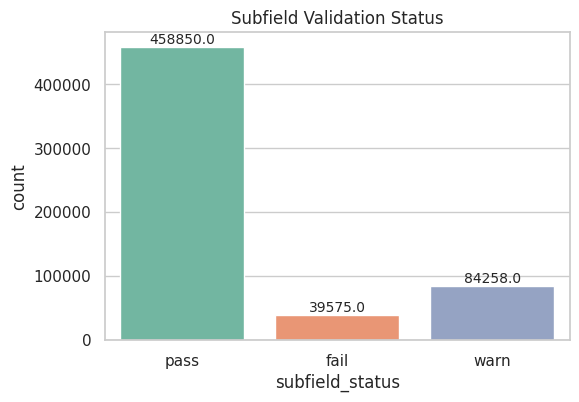

In [3]:
# 1. Bar plot: Subfield validation status
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="subfield_status", data=df, palette="Set2")

# Add counts on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}', 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10)

plt.title("Subfield Validation Status")
plt.savefig(os.path.join(OUTPUT_DIR, "fig_validation_status.png"), bbox_inches="tight")
plt.show()
plt.close()


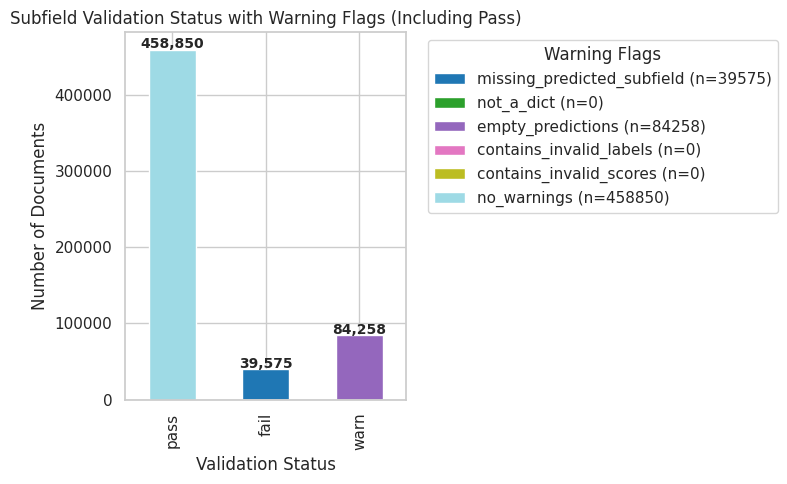

In [4]:
import matplotlib.pyplot as plt

# Define the flag columns
flag_cols = [
    "missing_predicted_subfield",
    "not_a_dict",
    "empty_predictions",
    "contains_invalid_labels",
    "contains_invalid_scores"
]

# Aggregate counts directly without creating a MultiIndex
pivot_df = df.groupby("subfield_status")[flag_cols].sum()

# Ensure all statuses are present, even if they have 0 warnings
for status in ["pass", "fail", "warn"]:
    if status not in pivot_df.index:
        pivot_df.loc[status] = 0

# Sort index to match logical order
pivot_df = pivot_df.loc[["pass", "fail", "warn"]]

# Compute total docs per flag for legend
flag_totals = {flag: int(df[flag].sum()) for flag in flag_cols}

# Add a "No warnings" column for pass docs with 0 flags
pivot_df["no_warnings"] = (
    df.groupby("subfield_status").size() - pivot_df.sum(axis=1)
).clip(lower=0)

# Add count to legend labels
legend_labels = [
    f"{col} (n={flag_totals.get(col, int(pivot_df[col].sum()))})"
    for col in pivot_df.columns
]

# Plot stacked bar
ax = pivot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    colormap="tab20"
)

# Replace legend with correct labels
ax.legend(legend_labels, title="Warning Flags", bbox_to_anchor=(1.05, 1), loc='upper left')

# Titles & labels
plt.title("Subfield Validation Status with Warning Flags (Including Pass)")
plt.xlabel("Validation Status")
plt.ylabel("Number of Documents")

# Add total doc count labels above bars
total_counts = df["subfield_status"].value_counts()
for i, status in enumerate(["pass", "fail", "warn"]):
    plt.text(
        i, total_counts.get(status, 0) + 2000,
        f"{total_counts.get(status, 0):,}",
        ha="center", fontsize=10, fontweight="bold"
    )

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_validation_status_combined.png"), bbox_inches="tight")
plt.show()
plt.close()


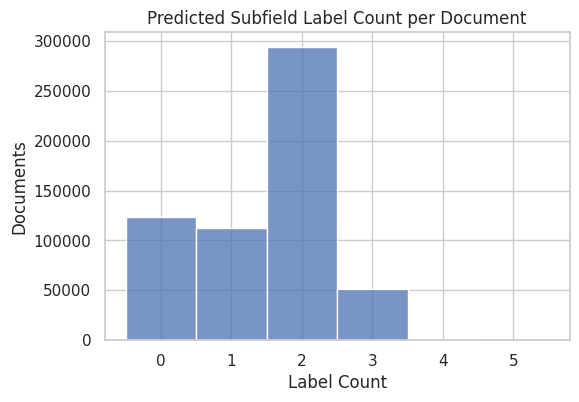

In [5]:
plt.figure(figsize=(6, 4))
sns.set_style("whitegrid")

# Make sure label_count is treated as discrete integers
ax = sns.histplot(df["label_count"].dropna(), binwidth=1, discrete=True)

# Set x-ticks exactly under each bar
xticks = sorted(df["label_count"].dropna().unique())
ax.set_xticks(xticks)
ax.set_xticklabels(xticks)

# Annotate bars
# for p in ax.patches:
#     height = p.get_height()
#     if height > 0:
#         ax.annotate(f'{int(height):,}',
#                     (p.get_x() + p.get_width() / 2., height),
#                     ha='center', va='bottom', fontsize=9)

plt.title("Predicted Subfield Label Count per Document")
plt.xlabel("Label Count")
plt.ylabel("Documents")
plt.savefig(os.path.join(OUTPUT_DIR, "fig_label_count_histogram.png"), bbox_inches="tight")
plt.show()
plt.close()


In [6]:
# 4. Bar plot: Top invalid labels
if all_invalid_labels:
    top_invalid = pd.Series(all_invalid_labels).sort_values(ascending=False).head(10)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=top_invalid.values, y=top_invalid.index, palette="Reds_r")
    plt.title("Top Invalid Predicted Subfield Labels")
    plt.xlabel("Frequency")
    plt.ylabel("Invalid Label")
    plt.savefig(os.path.join(OUTPUT_DIR, "fig_invalid_labels.png"), bbox_inches="tight")
    plt.show()
    plt.close()

In [7]:
from pymongo import MongoClient
import pprint

# Config
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
N_EXAMPLES = 5  # Number of examples per flag

# Connect
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# Define all the flag names and their MongoDB paths
flags = {
    "missing_predicted_subfield": "validation_info.checks.subfield_validation.flags.missing_predicted_subfield",
    "not_a_dict": "validation_info.checks.subfield_validation.flags.not_a_dict",
    "empty_predictions": "validation_info.checks.subfield_validation.flags.empty_predictions",
    "contains_invalid_labels": "validation_info.checks.subfield_validation.flags.contains_invalid_labels",
    "contains_invalid_scores": "validation_info.checks.subfield_validation.flags.contains_invalid_scores"
}

# Helper to get and print example documents
def fetch_and_print_examples(flag_name: str, flag_path: str, n: int = 5):
    print(f"\n🔍 Example documents for flag: **{flag_name}**")
    cursor = collection.find(
        {flag_path: True},
        {
            "_id": 1,
            "predicted_subfield": 1,
            flag_path: 1,
            "validation_info.checks.subfield_validation.status": 1
        }
    ).limit(n)

    found = False
    for doc in cursor:
        pprint.pprint(doc)
        print("-" * 60)
        found = True

    if not found:
        print("✅ No documents found with this flag!")

# Run for each flag
for flag_name, flag_path in flags.items():
    fetch_and_print_examples(flag_name, flag_path, N_EXAMPLES)

# Cleanup
client.close()



🔍 Example documents for flag: **missing_predicted_subfield**
{'_id': 100100350,
 'validation_info': {'checks': {'subfield_validation': {'flags': {'missing_predicted_subfield': True},
                                                        'status': 'fail'}}}}
------------------------------------------------------------
{'_id': 100059678,
 'validation_info': {'checks': {'subfield_validation': {'flags': {'missing_predicted_subfield': True},
                                                        'status': 'fail'}}}}
------------------------------------------------------------
{'_id': 100064598,
 'validation_info': {'checks': {'subfield_validation': {'flags': {'missing_predicted_subfield': True},
                                                        'status': 'fail'}}}}
------------------------------------------------------------
{'_id': 100053318,
 'validation_info': {'checks': {'subfield_validation': {'flags': {'missing_predicted_subfield': True},
                                    

In [ ]:
# import os
# from os import scandir
# from pathlib import Path
# from concurrent.futures import ThreadPoolExecutor
# from tqdm.auto import tqdm

# # Try fast JSON
# try:
#     import orjson as _json
#     def loads(b: bytes): return _json.loads(b)
# except Exception:
#     import json as _json
#     def loads(b: bytes): return _json.loads(b.decode('utf-8'))

# # CONFIG
# folder_path = "/mnt/d/data/final_database_republishable"
# output_file = Path("./merged_predicted_subfields.json")

# # Tune this: too high can slow down on a single disk.
# MAX_WORKERS = min(16, (os.cpu_count() or 4) * 2)
# CHUNKSIZE = 64  # batching for executor.map

# def iter_json_files(dirpath: str):
#     with scandir(dirpath) as it:
#         for entry in it:
#             # quickest filter: no stat calls
#             if entry.is_file() and entry.name.endswith(".json"):
#                 yield entry.path

# def process_file(path: str):
#     try:
#         with open(path, "rb") as f:  # read bytes for orjson
#             data = loads(f.read())
#         ps = data.get("predicted_subfield")
#         if isinstance(ps, dict):
#             corpusid = Path(path).stem
#             return corpusid, ps
#     except Exception:
#         pass
#     return None

# def main():
#     files = list(iter_json_files(folder_path))
#     merged = {}

#     with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
#         for res in tqdm(ex.map(process_file, files, chunksize=CHUNKSIZE),
#                         total=len(files), desc="Processing files", smoothing=0.0):
#             if res:
#                 cid, ps = res
#                 merged[cid] = ps

#     # Write with orjson if available for speed
#     try:
#         import orjson
#         with open(output_file, "wb") as f:
#             f.write(orjson.dumps(merged, option=orjson.OPT_INDENT_2))
#     except Exception:
#         import json
#         with open(output_file, "w", encoding="utf-8") as f:
#             json.dump(merged, f, indent=2, ensure_ascii=False)

#     print(f"✅ Merged {len(merged)} entries into {output_file}")

# if __name__ == "__main__":
#     main()


/home/mahmoud/rag/myenv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Processing files: 100%|██████████| 582724/582724 [57:39<00:00, 168.43it/s]


✅ Merged 543108 entries into merged_predicted_subfields.json


/tmp/ipykernel_3396531/3359189794.py:137: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax3.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
/tmp/ipykernel_3396531/3359189794.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.15, 1, 1])


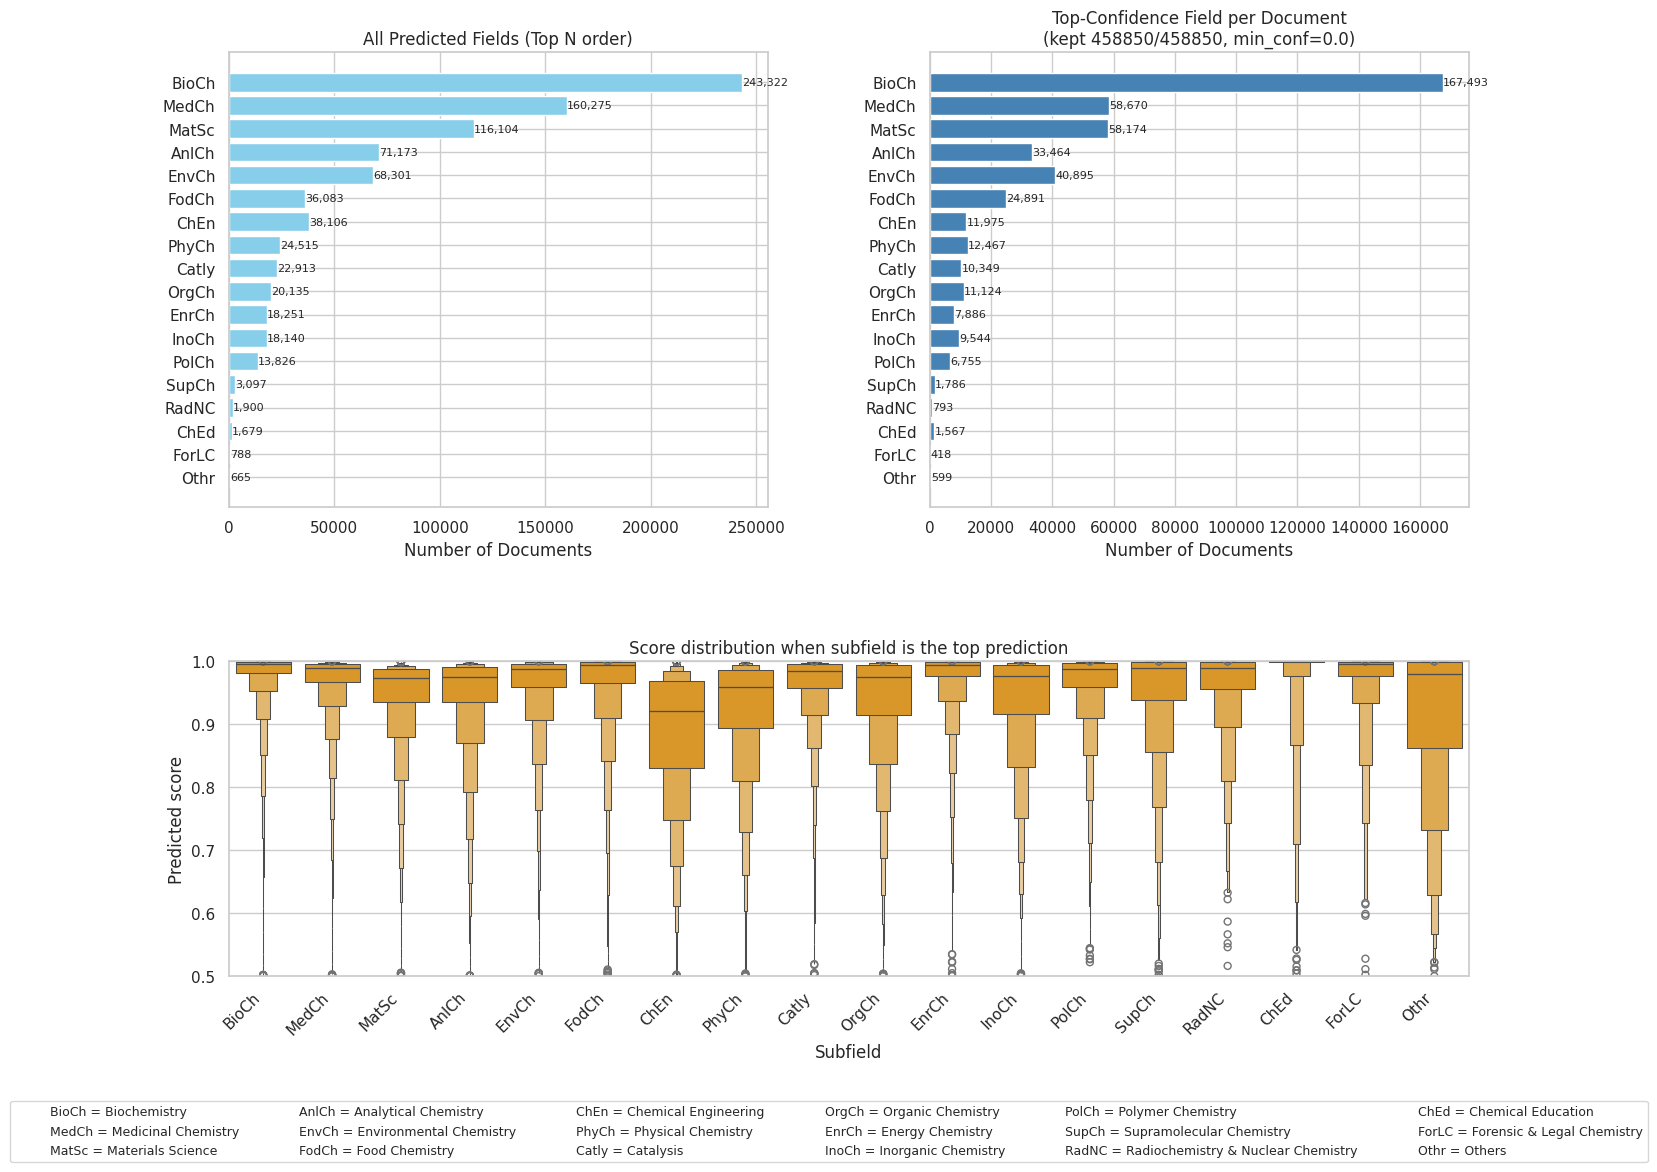

In [42]:
import json
from collections import Counter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# ---------------- Config ----------------
INPUT_JSON = "merged_predicted_subfields.json"
TOP_N = 18            # show top-N subfields everywhere
min_conf = 0.0        # filter for top-confidence counts
normalize = False     # bar charts as percentages instead of counts?

# Fixed abbreviation map (consistent, readable)
field_abbrev_map = {
    "Analytical Chemistry": "AnlCh",
    "Biochemistry": "BioCh",
    "Catalysis": "Catly",
    "Chemical Education": "ChEd",
    "Chemical Engineering": "ChEn",
    "Energy Chemistry": "EnrCh",
    "Environmental Chemistry": "EnvCh",
    "Food Chemistry": "FodCh",
    "Forensic & Legal Chemistry": "ForLC",
    "Inorganic Chemistry": "InoCh",
    "Materials Science": "MatSc",
    "Medicinal Chemistry": "MedCh",
    "Organic Chemistry": "OrgCh",
    "Others": "Othr",
    "Physical Chemistry": "PhyCh",
    "Polymer Chemistry": "PolCh",
    "Radiochemistry & Nuclear Chemistry": "RadNC",
    "Supramolecular Chemistry": "SupCh"
}

# ---------------- Load + build DataFrame ----------------
with open(INPUT_JSON, "r", encoding="utf-8") as f:
    merged = json.load(f)  # {corpusid: {subfield: score, ...}, ...}

# rows = corpusid, columns = subfields; fill missing with 0.0
df = pd.DataFrame.from_dict(merged, orient="index")
df = df.apply(pd.to_numeric, errors="coerce").fillna(0.0)

# Order categories by total mass and keep top N for plotting
cat_totals = df.sum().sort_values(ascending=False)
cats_top = cat_totals.head(TOP_N).index.tolist()
df_top = df[cats_top]

# Argmax label per doc (top subfield)
top_labels = df.idxmax(axis=1)

# Top score per doc (robust to pandas versions)
col_idx = df.columns.get_indexer(top_labels)
top_scores = df.to_numpy()[np.arange(len(df)), col_idx]

# DataFrame for boxen plot (top-only)
top_df = pd.DataFrame({
    "corpusid": df.index,
    "subfield": top_labels.values,
    "score": top_scores
})
top_df = top_df[top_df["subfield"].isin(cats_top)]

# ---------------- Counts for bar charts ----------------
# All predictions: count every predicted field present in JSON
all_counts = Counter()
for preds in merged.values():
    all_counts.update(preds.keys())

# Top-confidence counts: one per doc after min_conf filter
top_counts_ctr = Counter()
n_docs_seen = 0
n_docs_kept = 0
for preds in merged.values():
    if not preds:
        continue
    n_docs_seen += 1
    top_field, top_conf = max(preds.items(), key=lambda kv: kv[1])
    if top_conf >= min_conf:
        top_counts_ctr[top_field] += 1
        n_docs_kept += 1

# Restrict to Top N categories (same order everywhere)
all_counts_series = pd.Series({k: all_counts.get(k, 0) for k in cats_top})
top_counts_series = pd.Series({k: top_counts_ctr.get(k, 0) for k in cats_top})

# Optional normalization for bars
ylabel = "Number of Documents"
if normalize:
    if all_counts_series.sum():
        all_counts_series = 100 * all_counts_series / all_counts_series.sum()
    if top_counts_series.sum():
        top_counts_series = 100 * top_counts_series / top_counts_series.sum()
    ylabel = "Percentage of Documents (%)"

# Abbreviations for y/x tick labels
abbrevs = [field_abbrev_map.get(f, f[:5]) for f in cats_top]

# ---------------- Plot layout (2 rows) ----------------
fig = plt.figure(figsize=(16, 12))  # larger to avoid overlaps
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 0.9], hspace=0.4, wspace=0.3)

# Left (row 1, col 1): All predictions
ax1 = fig.add_subplot(gs[0, 0])
bars1 = ax1.barh(abbrevs, all_counts_series.values, color="skyblue")
ax1.invert_yaxis()
ax1.set_xlabel(ylabel)
ax1.set_title("All Predicted Fields (Top N order)")
# add some right padding to avoid label clipping
max1 = (all_counts_series.max() if not normalize else all_counts_series.max()) * 1.05
ax1.set_xlim(0, max1)
for bar in bars1:
    w = bar.get_width()
    ax1.text(w, bar.get_y() + bar.get_height()/2,
             f"{w:,.0f}" if not normalize else f"{w:.1f}%",
             va="center", ha="left", fontsize=8)

# Right (row 1, col 2): Top-confidence per doc
ax2 = fig.add_subplot(gs[0, 1])
bars2 = ax2.barh(abbrevs, top_counts_series.values, color="steelblue")
ax2.invert_yaxis()
ax2.set_xlabel(ylabel)
ax2.set_title(f"Top-Confidence Field per Document\n(kept {n_docs_kept}/{n_docs_seen}, min_conf={min_conf})")
max2 = (top_counts_series.max() if not normalize else top_counts_series.max()) * 1.05
ax2.set_xlim(0, max2)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w, bar.get_y() + bar.get_height()/2,
             f"{w:,.0f}" if not normalize else f"{w:.1f}%",
             va="center", ha="left", fontsize=8)

# Bottom (row 2, span both): Boxen plot of top scores
ax3 = fig.add_subplot(gs[1, :])
sns.boxenplot(data=top_df, x="subfield", y="score", color="#f59e0b", ax=ax3, order=cats_top)
ax3.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
ax3.set_title("Score distribution when subfield is the top prediction")
ax3.set_xlabel("Subfield")
ax3.set_ylabel("Predicted score")
ax3.set_ylim(0.5, 1.0)

# Standard legend at bottom; enough columns to make ~3 rows
handles = [
    plt.Line2D([0], [0], color='white', marker='o', markersize=8,
               label=f"{field_abbrev_map.get(k, k[:5])} = {k}")
    for k in cats_top
]
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=9, bbox_to_anchor=(0.5, -0.05))

# Reserve bottom margin for legend
plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.show()


/tmp/ipykernel_3396531/2039412718.py:147: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax3.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
/tmp/ipykernel_3396531/2039412718.py:156: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax4.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
/tmp/ipykernel_3396531/2039412718.py:172: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.15, 1, 1])


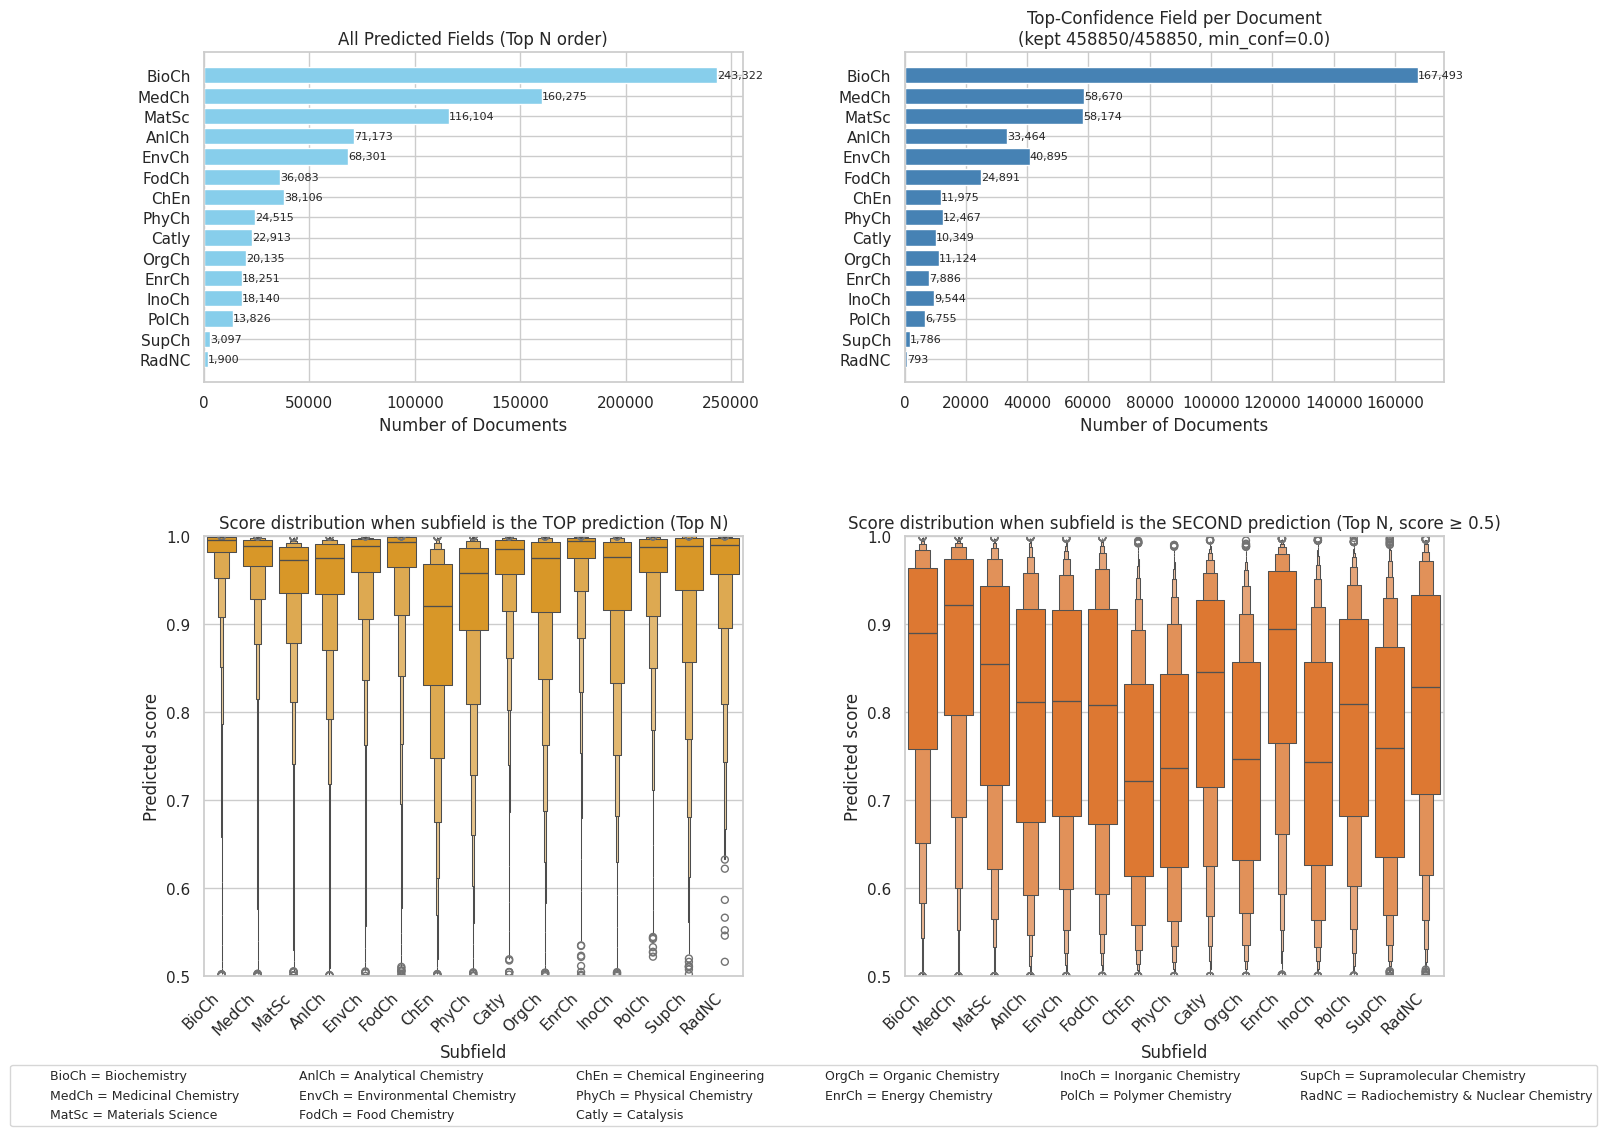

In [ ]:
import json
from collections import Counter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# ---------------- Config ----------------
INPUT_JSON = "merged_predicted_subfields.json"
TOP_N = 18            # show top-N subfields everywhere
min_conf = 0.0        # filter for top-confidence counts (bar charts)
second_min = 0.5      # only keep 2nd-place scores >= this for the right-bottom plot
normalize = False     # bar charts as percentages instead of counts?

# Fixed abbreviation map (consistent, readable)
field_abbrev_map = {
    "Analytical Chemistry": "AnlCh",
    "Biochemistry": "BioCh",
    "Catalysis": "Catly",
    "Chemical Education": "ChEd",
    "Chemical Engineering": "ChEn",
    "Energy Chemistry": "EnrCh",
    "Environmental Chemistry": "EnvCh",
    "Food Chemistry": "FodCh",
    "Forensic & Legal Chemistry": "ForLC",
    "Inorganic Chemistry": "InoCh",
    "Materials Science": "MatSc",
    "Medicinal Chemistry": "MedCh",
    "Organic Chemistry": "OrgCh",
    "Others": "Othr",
    "Physical Chemistry": "PhyCh",
    "Polymer Chemistry": "PolCh",
    "Radiochemistry & Nuclear Chemistry": "RadNC",
    "Supramolecular Chemistry": "SupCh"
}

# ---------------- Load + build DataFrame ----------------
with open(INPUT_JSON, "r", encoding="utf-8") as f:
    merged = json.load(f)  # {corpusid: {subfield: score, ...}, ...}

# rows = corpusid, columns = subfields; fill missing with 0.0
df = pd.DataFrame.from_dict(merged, orient="index")
df = df.apply(pd.to_numeric, errors="coerce").fillna(0.0)

# Order categories by total mass and keep top N for plotting
cat_totals = df.sum().sort_values(ascending=False)
cats_top = cat_totals.head(TOP_N).index.tolist()
df_top = df[cats_top]

# ---------------- Argmax (top1) labels & scores ----------------
top_labels = df.idxmax(axis=1)
col_idx_top = df.columns.get_indexer(top_labels)
top_scores = df.to_numpy()[np.arange(len(df)), col_idx_top]

top_df = pd.DataFrame({
    "corpusid": df.index,
    "subfield": top_labels.values,
    "score": top_scores
})
top_df = top_df[top_df["subfield"].isin(cats_top)]

# ---------------- Second-best labels & scores (if applicable) ----------------
arr = df.to_numpy()
order = np.argsort(arr, axis=1)[:, ::-1]  # descending column indices
second_idx = order[:, 1]                   # second-best column per row
second_labels = df.columns[second_idx].to_numpy()
second_scores = arr[np.arange(len(df)), second_idx]

second_df = pd.DataFrame({
    "corpusid": df.index,
    "subfield": second_labels,
    "score": second_scores
})
# keep only those with a meaningful second score and within Top N categories
second_df = second_df[(second_df["subfield"].isin(cats_top)) & (second_df["score"] >= second_min)]

# ---------------- Counts for bar charts ----------------
# All predictions: count every predicted field present in JSON
all_counts = Counter()
for preds in merged.values():
    all_counts.update(preds.keys())

# Top-confidence counts: one per doc after min_conf filter
top_counts_ctr = Counter()
n_docs_seen = 0
n_docs_kept = 0
for preds in merged.values():
    if not preds:
        continue
    n_docs_seen += 1
    top_field, top_conf = max(preds.items(), key=lambda kv: kv[1])
    if top_conf >= min_conf:
        top_counts_ctr[top_field] += 1
        n_docs_kept += 1

# Restrict to Top N categories (same order everywhere)
all_counts_series = pd.Series({k: all_counts.get(k, 0) for k in cats_top})
top_counts_series = pd.Series({k: top_counts_ctr.get(k, 0) for k in cats_top})

# Optional normalization for bars
ylabel = "Number of Documents"
if normalize:
    if all_counts_series.sum():
        all_counts_series = 100 * all_counts_series / all_counts_series.sum()
    if top_counts_series.sum():
        top_counts_series = 100 * top_counts_series / top_counts_series.sum()
    ylabel = "Percentage of Documents (%)"

# Abbreviations for tick labels (consistent order)
abbrevs = [field_abbrev_map.get(f, f[:5]) for f in cats_top]

# ---------------- Plot layout (2 rows x 2 cols) ----------------
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.6], hspace=0.4, wspace=0.3)

# Row 1, Col 1: All predictions
ax1 = fig.add_subplot(gs[0, 0])
bars1 = ax1.barh(abbrevs, all_counts_series.values, color="skyblue")
ax1.invert_yaxis()
ax1.set_xlabel(ylabel)
ax1.set_title("All Predicted Fields (Top N order)")
ax1.set_xlim(0, all_counts_series.max() * 1.05 if len(all_counts_series) else 1)
for bar in bars1:
    w = bar.get_width()
    ax1.text(w, bar.get_y() + bar.get_height()/2,
             f"{w:,.0f}" if not normalize else f"{w:.1f}%",
             va="center", ha="left", fontsize=8)

# Row 1, Col 2: Top-confidence per doc
ax2 = fig.add_subplot(gs[0, 1])
bars2 = ax2.barh(abbrevs, top_counts_series.values, color="steelblue")
ax2.invert_yaxis()
ax2.set_xlabel(ylabel)
ax2.set_title(f"Top-Confidence Field per Document\n(kept {n_docs_kept}/{n_docs_seen}, min_conf={min_conf})")
ax2.set_xlim(0, top_counts_series.max() * 1.05 if len(top_counts_series) else 1)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w, bar.get_y() + bar.get_height()/2,
             f"{w:,.0f}" if not normalize else f"{w:.1f}%",
             va="center", ha="left", fontsize=8)

# Row 2, Col 1: Top-1 score distribution
ax3 = fig.add_subplot(gs[1, 0])
sns.boxenplot(data=top_df, x="subfield", y="score", color="#f59e0b", ax=ax3, order=cats_top)
ax3.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
ax3.set_title("Score distribution when subfield is the TOP prediction")
ax3.set_xlabel("Subfield")
ax3.set_ylabel("Predicted score")
ax3.set_ylim(0.5, 1.0)

# Row 2, Col 2: Second-best score distribution (if applicable)
ax4 = fig.add_subplot(gs[1, 1])
sns.boxenplot(data=second_df, x="subfield", y="score", color="#f97316", ax=ax4, order=cats_top)
ax4.set_xticklabels([field_abbrev_map.get(f, f[:5]) for f in cats_top], rotation=45, ha="right")
ax4.set_title(f"Score distribution when subfield is the SECOND prediction")
ax4.set_xlabel("Subfield")
ax4.set_ylabel("Predicted score")
ax4.set_ylim(0.5, 1.0)

# Legend at the bottom (standard Matplotlib)
handles = [
    plt.Line2D([0], [0], color='white', marker='o', markersize=8,
               label=f"{field_abbrev_map.get(k, k[:5])} = {k}")
    for k in cats_top
]
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))  # tweak lower if you want it further down

# Reserve bottom margin for legend
plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.show()
